# Bayes y distribuciones discretas

## Objetivo
Entender tasas base y distinguir una probabilidad individual de la distribución de un conteo.

**Datos:** ejemplos analíticos o simulaciones didácticas; no representan clientes ni estimaciones de mercado.

## Preparación
Python 3.11 o posterior, NumPy, SciPy y Matplotlib. Todo se genera aquí; no necesita internet. Lee la fórmula y predice el resultado antes de ejecutar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.prop_cycle': plt.cycler(color=['#285A8E','#C77C36','#687D45'])})
rng = np.random.default_rng(20261025)


## 1. Actualizar una probabilidad

Con prevalencia $p$, sensibilidad $s$ y falsos positivos $f$, Bayes da $P(F|A)=sp/[sp+f(1-p)]$. Comparamos sensibilidad fija 0.9 con dos tasas de falsos positivos.

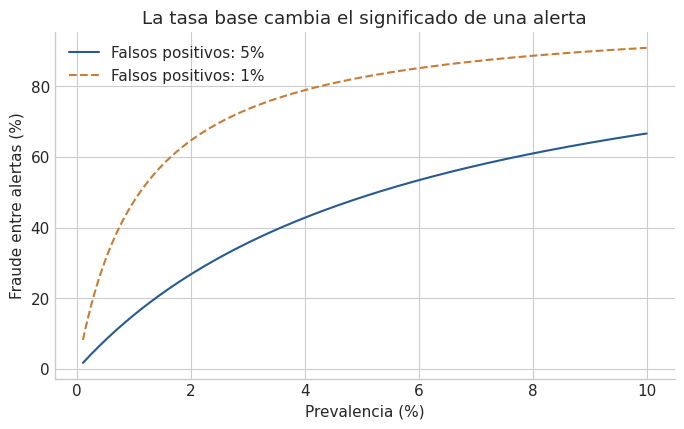

Con prevalencia 1% y FPR 5%: 0.15384615384615385


In [2]:
prevalencias=np.linspace(.001,.1,200)
posterior=lambda p,f: .9*p/(.9*p+f*(1-p))
fig,ax=plt.subplots()
for f,estilo in [(.05,'-'),(.01,'--')]:
    ax.plot(100*prevalencias,100*posterior(prevalencias,f),estilo,label=f'Falsos positivos: {100*f:.0f}%')
ax.set(xlabel='Prevalencia (%)',ylabel='Fraude entre alertas (%)',title='La tasa base cambia el significado de una alerta')
ax.legend(); plt.show()
print('Con prevalencia 1% y FPR 5%:',posterior(.01,.05))

**Lectura del resultado.** Con prevalencia 1% y falsos positivos 5%, aproximadamente 15.38% de alertas son fraude. Reducir falsos positivos mejora esa proporción, manteniendo los demás parámetros fijos.

## 2. Contar eventos independientes

Si $X$ cuenta incumplimientos entre $n=20$ exposiciones independientes con igual $p=0.1$, entonces $P(X=k)=\binom{20}{k}p^k(1-p)^{20-k}$. Su media es $np=2$ y su varianza $np(1-p)=1.8$. La independencia es una hipótesis fuerte.

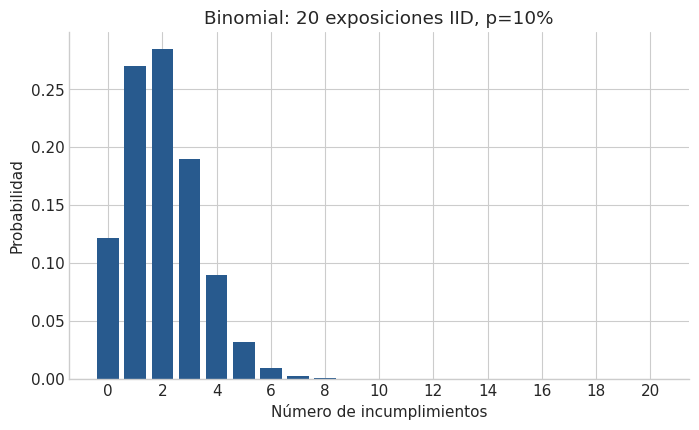

Probabilidad de al menos uno: 0.8784233454094308


In [3]:
k=np.arange(21)
pmf=stats.binom.pmf(k,20,.1)
fig,ax=plt.subplots()
ax.bar(k,pmf,color='#285A8E')
ax.set(xlabel='Número de incumplimientos',ylabel='Probabilidad',title='Binomial: 20 exposiciones IID, p=10%')
ax.set_xticks(np.arange(0,21,2)); plt.show()
print('Probabilidad de al menos uno:',1-stats.binom.pmf(0,20,.1))

**Lectura del resultado.** La probabilidad de al menos un incumplimiento es aproximadamente 87.84%. Si existe dependencia, conocer solo p no determina esta distribución.

## Practica antes de ver la solución

¿Cuál es P(X=0) con 20 exposiciones IID y p=0.1? ¿Esperar dos incumplimientos significa observar exactamente dos?

In [4]:
# Escribe aquí tu razonamiento y tu cálculo.


## Solución razonada

P(X=0)=0.9²⁰≈0.12158. La esperanza 2 es un promedio de repeticiones; no garantiza un conteo observado de dos.

## Comprobaciones

Estas pruebas contrastan identidades, referencias analíticas y tolerancias; no prueban teoremas ni validan modelos reales.

In [5]:
assert np.isclose(posterior(.01,.05),2/13)
assert np.isclose(pmf.sum(),1)
assert np.isclose(k@pmf,2)
assert np.isclose(((k-2)**2)@pmf,1.8)
assert np.isclose(pmf[0],.9**20)
print('Bayes, normalización y momentos: OK')

Bayes, normalización y momentos: OK


## Siguiente paso

Cambia un parámetro, anticipa el efecto y explica por qué ocurre. Vuelve a ejecutar desde un kernel limpio. Consulta el índice del curso para la lección teórica relacionada.